In [1]:
# YOLO - Object Detection (You Only Look Once)
# Library: ultralytics (YOLOv8 / YOLO11)
#
# Needs: pip install ultralytics
# (this also installs PyTorch, which is a big download - a few GB on some systems)
#
# What's different from classification (scripts 34 and 44)?
#   Classification : "this image is a cat"                  -> one label per image
#   Detection      : "a cat at (x1,y1)-(x2,y2), 91% sure,
#                     and a dog at ..."                      -> many objects, each with a box
#
# YOLO looks at the whole image ONCE and predicts all the boxes together, which is
# why it is fast enough for video and webcams.
#
# The first run downloads pretrained weights automatically (a few MB for the 'n' nano model).

import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage import data
from ultralytics import YOLO


Classes the model knows: 80
['person', 'bicycle', 'car', 'motorcycle', 'airplane', 'bus', 'train', 'truck', 'boat', 'traffic light', 'fire hydrant', 'stop sign', 'parking meter', 'bench', 'bird'] ...


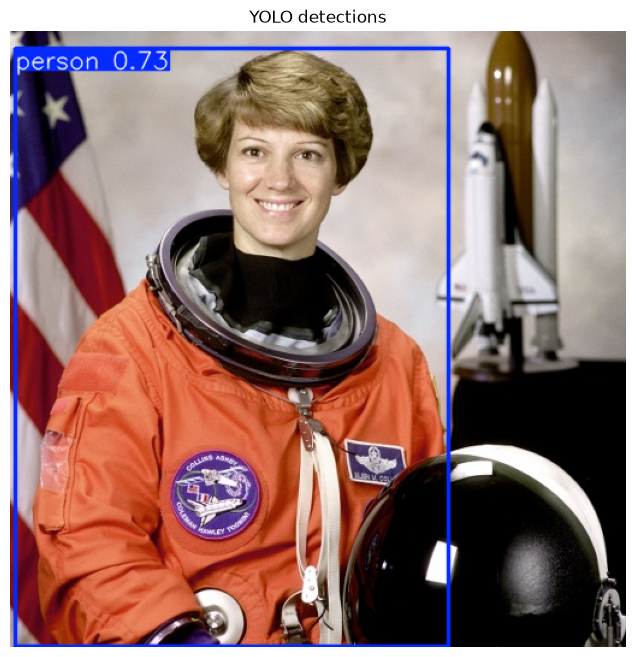

In [2]:
# ============================================================
# PART 1 - Detect objects with a PRETRAINED model (no training needed)
# ============================================================

# ---- 1. Load a model pretrained on COCO (80 everyday object types) ----
# sizes: n (nano, fastest) < s < m < l < x (biggest, most accurate)
# newer alternative: YOLO("yolo11n.pt")
model = YOLO("yolov8n.pt")

print("Classes the model knows:", len(model.names))
print(list(model.names.values())[:15], "...")     # person, bicycle, car, ...

# ---- 2. Get an image to test on ----
# using skimage's sample photo so this runs with no setup. To use your own photo:
#   image_path = "../Datasets/my_photo.jpg"
image_path = "sample_photo.jpg"
cv2.imwrite(image_path, cv2.cvtColor(data.astronaut(), cv2.COLOR_RGB2BGR))

# ---- 3. Run detection ----
# conf = minimum confidence; boxes the model is less sure about than this are dropped
results = model.predict(source=image_path, conf=0.25, verbose=False)
result = results[0]       # one result object per image

# ---- 4. Draw the boxes and display ----
annotated = result.plot()                              # image with boxes + labels drawn (BGR)
annotated_rgb = cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(8, 8))
plt.imshow(annotated_rgb)
plt.title("YOLO detections")
plt.axis("off")
plt.show()

In [3]:
# ---- 5. Read the raw detection results ----
boxes = result.boxes
print(f"\nObjects detected: {len(boxes)}")

for box in boxes:
    class_id = int(box.cls[0])
    class_name = model.names[class_id]
    confidence = float(box.conf[0])
    x1, y1, x2, y2 = box.xyxy[0].tolist()        # corners: top-left and bottom-right
    print(f"{class_name:12s} confidence={confidence:.2f}  box=({x1:.0f},{y1:.0f})-({x2:.0f},{y2:.0f})")

# ---- 6. Count objects per class ----
detected_classes = [model.names[int(c)] for c in boxes.cls]
counts = {name: detected_classes.count(name) for name in set(detected_classes)}
print("\nCount per class:", counts)

# ---- 7. Crop out each detected object ----
original = cv2.imread(image_path)
for i, box in enumerate(boxes):
    x1, y1, x2, y2 = map(int, box.xyxy[0].tolist())
    crop = original[y1:y2, x1:x2]
    cv2.imwrite(f"crop_{i}_{model.names[int(box.cls[0])]}.jpg", crop)


Objects detected: 1
person       confidence=0.73  box=(5,14)-(364,511)

Count per class: {'person': 1}


In [4]:
# ---- 8. Effect of the confidence threshold ----
# lower threshold = more detections but more false alarms
# higher threshold = fewer detections but more trustworthy ones
for threshold in [0.1, 0.25, 0.5, 0.75]:
    r = model.predict(source=image_path, conf=threshold, verbose=False)[0]
    print(f"conf >= {threshold:<4}  ->  {len(r.boxes)} detections")

# ---- 9. Video / webcam (uncomment to try - press 'q' to quit) ----
# for video file:  model.predict(source="my_video.mp4", show=True, conf=0.4)
# for webcam:      model.predict(source=0, show=True, conf=0.4)


conf >= 0.1   ->  2 detections
conf >= 0.25  ->  1 detections
conf >= 0.5   ->  1 detections
conf >= 0.75  ->  0 detections


In [6]:
# ============================================================
# PART 2 - Train YOLO on your OWN data (fine-tuning)
# ============================================================
# Pretrained models only know the 80 COCO classes. To detect something custom
# (helmets, tomato ripeness, a specific logo...) you train on labelled images.
#
# Labelled data format - two folders, plus one text file per image:
#
#   my_dataset/
#     images/train/img1.jpg   labels/train/img1.txt
#     images/val/img9.jpg     labels/val/img9.txt
#
# each line of a label .txt = one object:   class_id  x_center  y_center  width  height
# (all four box values scaled to 0-1 by the image size). Tools like Roboflow,
# LabelImg and CVAT create these files for you.
#
# plus a small data.yaml that points to them:
#
#   path: my_dataset
#   train: images/train
#   val: images/val
#   names:
#     0: helmet
#     1: no_helmet


In [ ]:
# ---- 10. Quick smoke test - train 3 epochs on 'coco8' ----
# coco8 is a tiny 8-image dataset that ultralytics downloads for you. It is only
# useful to check your setup works - the accuracy will be meaningless.
train_model = YOLO("yolov8n.pt")      # start FROM pretrained weights (transfer learning)

train_results = train_model.train(
    data="coco8.yaml",        # replace with "my_dataset/data.yaml" for real work
    epochs=3,                 # real projects: 50-300
    imgsz=640,
    batch=8,
    project="runs",
    name="demo_train",
)

# ---- 11. Evaluate on the validation set ----
metrics = train_model.val()
print("mAP50    :", metrics.box.map50)     # accuracy at IoU threshold 0.5
print("mAP50-95 :", metrics.box.map)       # stricter, averaged over thresholds (main metric)
print("Precision:", metrics.box.mp)
print("Recall   :", metrics.box.mr)

# mAP (mean Average Precision) is THE standard detection metric. It checks both
# "did you find the object?" and "is your box in the right place?" (IoU = overlap
# between predicted and true box).

New https://pypi.org/project/ultralytics/8.4.182 available  Update with 'pip install -U ultralytics'
Ultralytics 8.3.230  Python-3.13.5 torch-2.9.1+cpu CPU (AMD Ryzen 7 5800H with Radeon Graphics)
engine\trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=coco8.yaml, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=3, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=False, name=demo_train, nbs=64, nms=False, opset=None, op

In [ ]:
# ---- 12. Use your trained model ----
# training saves the best weights at:  runs/demo_train/weights/best.pt
# (this is the same kind of best.pt file as in your Flask GitHub project)
best_model = YOLO("runs/demo_train/weights/best.pt")
best_results = best_model.predict(source=image_path, conf=0.25, verbose=False)
print("Detections with the trained model:", len(best_results[0].boxes))

# ---- 13. Export for deployment ----
# best_model.export(format="onnx")     # runs without PyTorch, e.g. in other languages
# the same best.pt can be loaded inside a Flask or FastAPI app (scripts 37 and 38):
#   model = YOLO("models/best.pt")  then  model.predict(uploaded_image)